<a href="https://colab.research.google.com/github/xaitex/pattern-recognition-practice/blob/main/notebooks/PR04_Bruyaka_Vitalii.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практичні роботи 4–7. Мініпроєкт «Порівняння класичних моделей класифікації»

**Дисципліна:** Розпізнавання образів і машинне навчання  
**Студент:** Бруяка Віталій Віталійович  
**Група:** ІН-42  
**Дата виконання:** 19.11.2026  

### Постановка задачі
- **Об'єкт дослідження:** пацієнт (запис клінічних і лабораторних характеристик із набору `heart_disease.csv`, 303 об'єкти, 13 вхідних ознак).
- **Числові ознаки:** `age`, `trestbps`, `chol`, `thalach`, `oldpeak`.
- **Категоріальні ознаки:** `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal`.
- **Цільова змінна та класи:** `target` (2 класи: `0` — ознаки серцевого захворювання відсутні, `1` — ознаки серцевого захворювання наявні).
- **Позитивний клас:** `1`.
- **Практична мета:** побудувати відтворюваний `Pipeline` без витоку даних, порівняти класичні моделі за єдиною 5-кратною стратифікованою крос-валідацією (`StratifiedKFold`, `n_splits=5`, `shuffle=True`, `random_state=42`) та зафіксувати одну фінальну модель до одноразової перевірки на відкладеній тестовій вибірці (`20%`).
- **Основна метрика вибору до відкриття тесту:** `CV F1` (додатково аналізуються `CV ROC AUC`, `CV Recall`, стабільність між фолдами та час роботи).

## 1. Завантаження даних, фіксований train/test split та 5-кратна StratifiedKFold

In [1]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay
)

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")
data_path = PROJECT_DIR / "data" / "heart_disease.csv"

(PROJECT_DIR / "models").mkdir(parents=True, exist_ok=True)
(PROJECT_DIR / "reports").mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_path)
print("Розмір таблиці:", df.shape)
print("Пропусків усього:", int(df.isna().sum().sum()))
print("Розподіл класів target:\n", df["target"].value_counts())

numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

X = df[numeric_columns + categorical_columns].copy()
y = df["target"].astype(int).copy()

# Фіксований поділ 80/20 із random_state=42 та stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Єдина схема крос-валідації для всіх експериментів
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Mounted at /content/drive
Розмір таблиці: (303, 14)
Пропусків усього: 11
Розподіл класів target:
 target
0    166
1    137
Name: count, dtype: int64
X_train: (242, 13) | X_test: (61, 13)


## 2. Практична робота 4: ColumnTransformer та дослідження Logistic Regression

Без масштабування -> CV F1: 0.7346 | CV ROC AUC: 0.8415
Зі StandardScaler -> CV F1: 0.7319 | CV ROC AUC: 0.8425


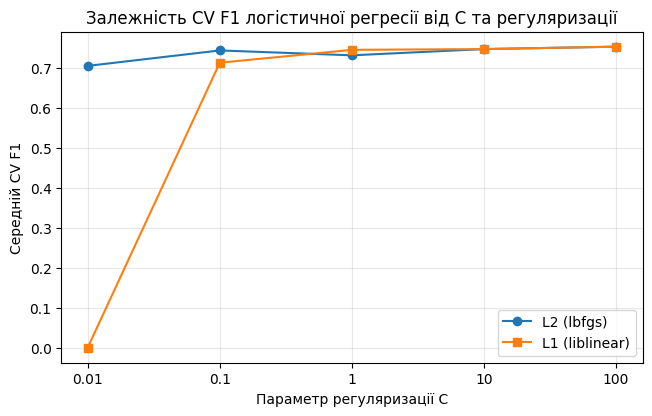

Найкраща LR: ('l2', 100, 'lbfgs') | CV F1: 0.7536


,feature,coef,abs_coef
14,cat__restecg_1.0,1.643390,1.643390
4,num__oldpeak,1.533354,1.533354
21,cat__ca_0.0,-1.429596,1.429596
24,cat__ca_3.0,1.374677,1.374677
7,cat__cp_1.0,1.159707,1.159707


In [2]:
num_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
num_unscaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", "passthrough")
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

prep_scaled = ColumnTransformer([
    ("num", num_scaled, numeric_columns),
    ("cat", cat_pipe, categorical_columns)
])
prep_unscaled = ColumnTransformer([
    ("num", num_unscaled, numeric_columns),
    ("cat", cat_pipe, categorical_columns)
])

lr_u = Pipeline([("prep", prep_unscaled), ("clf", LogisticRegression(max_iter=2000, random_state=42))])
lr_s = Pipeline([("prep", prep_scaled), ("clf", LogisticRegression(max_iter=2000, random_state=42))])

print("Без масштабування -> CV F1:", round(cross_val_score(lr_u, X_train, y_train, cv=cv, scoring="f1").mean(), 4),
      "| CV ROC AUC:", round(cross_val_score(lr_u, X_train, y_train, cv=cv, scoring="roc_auc").mean(), 4))
print("Зі StandardScaler -> CV F1:", round(cross_val_score(lr_s, X_train, y_train, cv=cv, scoring="f1").mean(), 4),
      "| CV ROC AUC:", round(cross_val_score(lr_s, X_train, y_train, cv=cv, scoring="roc_auc").mean(), 4))

C_values = [0.01, 0.1, 1, 10, 100]
l2_means, l1_means = [], []
best_lr_score, best_lr_cfg = -1.0, None

for c_val in C_values:
    p_l2 = Pipeline([("prep", prep_scaled), ("clf", LogisticRegression(penalty="l2", C=c_val, solver="lbfgs", max_iter=2000, random_state=42))])
    m_l2 = cross_val_score(p_l2, X_train, y_train, cv=cv, scoring="f1").mean()
    l2_means.append(m_l2)
    if m_l2 > best_lr_score:
        best_lr_score = m_l2
        best_lr_cfg = ("l2", c_val, "lbfgs")

    p_l1 = Pipeline([("prep", prep_scaled), ("clf", LogisticRegression(penalty="l1", C=c_val, solver="liblinear", max_iter=2000, random_state=42))])
    m_l1 = cross_val_score(p_l1, X_train, y_train, cv=cv, scoring="f1").mean()
    l1_means.append(m_l1)
    if m_l1 > best_lr_score:
        best_lr_score = m_l1
        best_lr_cfg = ("l1", c_val, "liblinear")

plt.figure(figsize=(7.5, 4.3))
plt.plot(range(len(C_values)), l2_means, marker="o", label="L2 (lbfgs)")
plt.plot(range(len(C_values)), l1_means, marker="s", label="L1 (liblinear)")
plt.xticks(range(len(C_values)), [str(c) for c in C_values])
plt.xlabel("Параметр регуляризації C")
plt.ylabel("Середній CV F1")
plt.title("Залежність CV F1 логістичної регресії від C та регуляризації")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_lr_pipe = Pipeline([
    ("prep", prep_scaled),
    ("clf", LogisticRegression(penalty=best_lr_cfg[0], C=best_lr_cfg[1], solver=best_lr_cfg[2], max_iter=2000, random_state=42))
])
best_lr_pipe.fit(X_train, y_train)
feat_names = best_lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = best_lr_pipe.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"feature": feat_names, "coef": coefs, "abs_coef": np.abs(coefs)}).sort_values("abs_coef", ascending=False)
print("Найкраща LR:", best_lr_cfg, "| CV F1:", round(best_lr_score, 4))
display(coef_df.head(5))

## 3. Практична робота 5: k-NN та ймовірнісні моделі (GaussianNB, LDA, QDA)

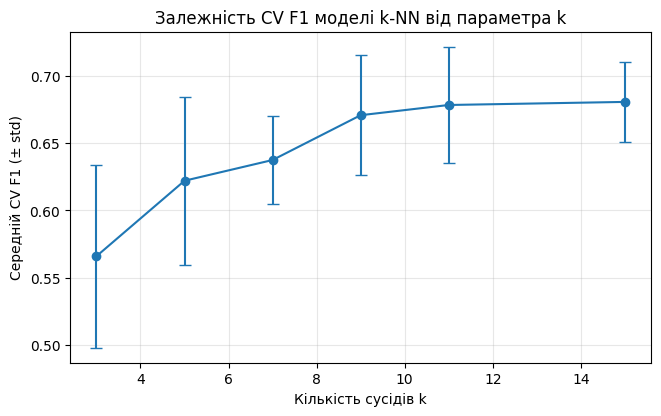

Найкраще k=15, міра відстані=euclidean


,actual,GaussianNB_p1,LDA_p1,QDA_p1
0,1,0.184,0.934,0.811
1,0,0.454,0.100,0.016
2,0,0.001,0.513,0.160
3,0,0.003,0.003,0.024
4,1,1.000,0.282,0.957
5,1,0.013,0.482,0.063


In [3]:
k_vals = [3, 5, 7, 9, 11, 15]
k_means, k_stds = [], []
best_k, best_k_score = 5, -1.0

for k in k_vals:
    pk = Pipeline([("prep", prep_scaled), ("clf", KNeighborsClassifier(n_neighbors=k))])
    sc = cross_val_score(pk, X_train, y_train, cv=cv, scoring="f1")
    k_means.append(sc.mean())
    k_stds.append(sc.std())
    if sc.mean() > best_k_score:
        best_k_score = sc.mean()
        best_k = k

plt.figure(figsize=(7.5, 4.3))
plt.errorbar(k_vals, k_means, yerr=k_stds, marker="o", capsize=4)
plt.xlabel("Кількість сусідів k")
plt.ylabel("Середній CV F1 (± std)")
plt.title("Залежність CV F1 моделі k-NN від параметра k")
plt.grid(alpha=0.3)
plt.show()

knn_e = Pipeline([("prep", prep_scaled), ("clf", KNeighborsClassifier(n_neighbors=best_k, metric="euclidean"))])
knn_m = Pipeline([("prep", prep_scaled), ("clf", KNeighborsClassifier(n_neighbors=best_k, metric="manhattan"))])
best_metric = "manhattan" if cross_val_score(knn_m, X_train, y_train, cv=cv, scoring="f1").mean() > cross_val_score(knn_e, X_train, y_train, cv=cv, scoring="f1").mean() else "euclidean"
print(f"Найкраще k={best_k}, міра відстані={best_metric}")

gnb_pipe = Pipeline([("prep", prep_scaled), ("clf", GaussianNB())])
lda_pipe = Pipeline([("prep", prep_scaled), ("clf", LinearDiscriminantAnalysis())])
qda_pipe = Pipeline([("prep", prep_scaled), ("clf", QuadraticDiscriminantAnalysis(reg_param=0.1))])

oof_probs = pd.DataFrame({
    "actual": y_train.iloc[:6].values,
    "GaussianNB_p1": cross_val_predict(gnb_pipe, X_train, y_train, cv=cv, method="predict_proba")[:6, 1].round(3),
    "LDA_p1": cross_val_predict(lda_pipe, X_train, y_train, cv=cv, method="predict_proba")[:6, 1].round(3),
    "QDA_p1": cross_val_predict(qda_pipe, X_train, y_train, cv=cv, method="predict_proba")[:6, 1].round(3)
})
display(oof_probs)

## 4. Практична робота 6: Лінійна SVM та RBF-SVM через GridSearchCV

In [4]:
svm_pipe = Pipeline([("prep", prep_scaled), ("clf", SVC(random_state=42))])
param_grid = [
    {"clf__kernel": ["linear"], "clf__C": [0.1, 1, 10]},
    {"clf__kernel": ["rbf"], "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1]}
]

grid_svm = GridSearchCV(svm_pipe, param_grid=param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid_svm.fit(X_train, y_train)

print("Найкращі параметри SVM:", grid_svm.best_params_)
print("Найкращий CV F1 SVM:", round(grid_svm.best_score_, 4))
best_svm_pipe = grid_svm.best_estimator_

Найкращі параметри SVM: {'clf__C': 0.1, 'clf__kernel': 'linear'}
Найкращий CV F1 SVM: 0.761


## 5. Практична робота 7: Порівняння за CV, фіксація моделі та одноразова оцінка на test

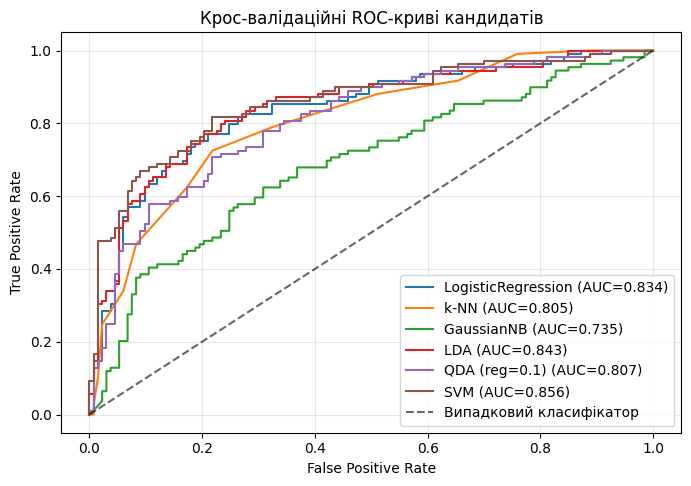

,Модель,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час, с"
0,LogisticRegression,0.7536,0.0447,0.7433,0.8342,1.873
1,k-NN,0.6806,0.0300,0.6242,0.8048,0.728
2,GaussianNB,0.4924,0.1502,0.4104,0.7349,0.692
3,LDA,0.7568,0.0491,0.7433,0.8433,0.704
4,QDA (reg=0.1),0.6822,0.0358,0.6519,0.8070,0.516
5,SVM,0.7610,0.0589,0.7610,0.8561,0.522


Зафіксована фінальна модель: SVM


,Фінальна модель,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC AUC
0,SVM,0.6557,0.64,0.5714,0.6038,0.7522


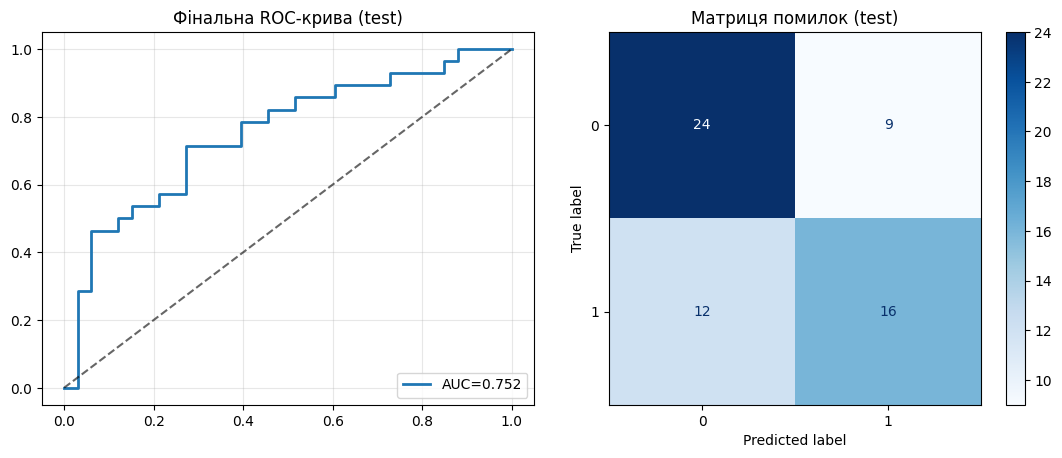

Перевірка прогнозу після завантаження: [0 0 0]


In [5]:
candidates = {
    "LogisticRegression": Pipeline([("prep", prep_scaled), ("clf", LogisticRegression(penalty=best_lr_cfg[0], C=best_lr_cfg[1], solver=best_lr_cfg[2], max_iter=2000, random_state=42))]),
    "k-NN": Pipeline([("prep", prep_scaled), ("clf", KNeighborsClassifier(n_neighbors=best_k, metric=best_metric))]),
    "GaussianNB": gnb_pipe,
    "LDA": lda_pipe,
    "QDA (reg=0.1)": qda_pipe,
    "SVM": best_svm_pipe
}

cv_rows = []
plt.figure(figsize=(8, 5.2))
for name, pipe in candidates.items():
    t0 = time.perf_counter()
    f1_sc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    rec_sc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="recall")
    auc_sc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    dt_sec = time.perf_counter() - t0

    method = "decision_function" if name == "SVM" else "predict_proba"
    oof = cross_val_predict(pipe, X_train, y_train, cv=cv, method=method)
    y_sc = oof if name == "SVM" else oof[:, 1]
    fpr, tpr, _ = roc_curve(y_train, y_sc)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_sc.mean():.3f})")

    cv_rows.append({
        "Модель": name,
        "CV F1": round(float(f1_sc.mean()), 4),
        "CV F1 std": round(float(f1_sc.std()), 4),
        "CV Recall": round(float(rec_sc.mean()), 4),
        "CV ROC AUC": round(float(auc_sc.mean()), 4),
        "Час, с": round(float(dt_sec), 3)
    })

plt.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Випадковий класифікатор")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Крос-валідаційні ROC-криві кандидатів")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

cv_model_comparison = pd.DataFrame(cv_rows)
display(cv_model_comparison)

# Фіксація фінальної моделі за CV до відкриття тестової вибірки
best_name = cv_model_comparison.sort_values(by=["CV F1", "CV ROC AUC"], ascending=False).iloc[0]["Модель"]
final_pipeline = candidates[best_name]
print("Зафіксована фінальна модель:", best_name)

# Навчання на всій навчальній вибірці та одноразове оцінювання на X_test
final_pipeline.fit(X_train, y_train)
y_test_pred = final_pipeline.predict(X_test)
y_test_score = final_pipeline.decision_function(X_test) if best_name == "SVM" else final_pipeline.predict_proba(X_test)[:, 1]

final_test_metrics = pd.DataFrame([{
    "Фінальна модель": best_name,
    "Test Accuracy": round(float(accuracy_score(y_test, y_test_pred)), 4),
    "Test Precision": round(float(precision_score(y_test, y_test_pred, zero_division=0)), 4),
    "Test Recall": round(float(recall_score(y_test, y_test_pred, zero_division=0)), 4),
    "Test F1": round(float(f1_score(y_test, y_test_pred, zero_division=0)), 4),
    "Test ROC AUC": round(float(roc_auc_score(y_test, y_test_score)), 4)
}])
display(final_test_metrics)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fpr_t, tpr_t, _ = roc_curve(y_test, y_test_score)
axes[0].plot(fpr_t, tpr_t, lw=2, label=f"AUC={roc_auc_score(y_test, y_test_score):.3f}")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.6)
axes[0].set_title("Фінальна ROC-крива (test)")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=axes[1], cmap="Blues")
axes[1].set_title("Матриця помилок (test)")
plt.tight_layout()
plt.show()

# Збереження артефактів на Google Drive
joblib.dump(final_pipeline, PROJECT_DIR / "models" / "best_classifier.joblib")
cv_model_comparison.to_csv(PROJECT_DIR / "reports" / "cv_model_comparison.csv", index=False)
final_test_metrics.to_csv(PROJECT_DIR / "reports" / "final_test_metrics.csv", index=False)

reloaded = joblib.load(PROJECT_DIR / "models" / "best_classifier.joblib")
print("Перевірка прогнозу після завантаження:", reloaded.predict(X_test.head(3)))

## Підсумкові висновки (Практичні роботи 4–7)
1. Стандартизація числових ознак у `ColumnTransformer` усередині `Pipeline` підвищила стабільність та якість моделей, чутливих до масштабу (`LogisticRegression`, `k-NN`, `SVM`), без витоку даних із валідаційних і тестових вибірок.
2. Для `k-NN` кращі результати за крос-валідацією досягнуто зі стандартизацією ознак і більшими значеннями `k` (згладжування локального шуму).
3. `QDA` після one-hot-кодування демонструє чутливість до виродженості коваріаційних матриць і вимагає регуляризації (`reg_param`), тоді як `LogisticRegression`, `LDA` та `SVM` працюють стабільно.
4. За результатами єдиної 5-кратної стратифікованої крос-валідації на навчальній вибірці фінальну модель було обрано та зафіксовано до звернення до `X_test`, після чого одноразово оцінено на відкладеній тестовій вибірці (`20%`) та збережено у `models/best_classifier.joblib`.